# Imports and Functions

In [1]:
import os,sys
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import astropy
import h5py
sys.path.append('../../code/misc')
#import webplotdigitizer as wpd
from scipy.special import erf

%matplotlib inline
%load_ext autoreload
%autoreload 2
 
from scipy.stats import chi2 as chi2_scipy
from scipy.optimize import dual_annealing
from scipy.optimize import minimize
from scipy.integrate import quad
from math import sqrt, cos, exp, pi, sin

import matplotlib.pyplot as plt
from matplotlib import rc
from matplotlib import rcParams

from scipy.special import factorial
from scipy.special import gammaln

from astropy.coordinates import SkyCoord
from astropy import units as u

In [2]:
def loadFile(fileString):
    in_file = str(fileString + '/outputFile.h5')
    with h5py.File(in_file, 'r') as h5f:
        # Read each dataset back into memory
        counts = h5f['counts'][:]
        det_res = h5f['det_res'][:]
        exp = h5f['exp'][()]
        cin_min = h5f['cin_min'][:]
        cin_max = h5f['cin_max'][:]
        cout_min = h5f['cout_min'][:]
        cout_max = h5f['cout_max'][:]
        flux = h5f['flux'][:]
        effA = h5f['effA'][:]

    #We store our dec and ra separately, and unpack them here
    coordsFile = (fileString + '/declensionInfo.txt')
    with open(coordsFile, 'r') as textFile:
        lineIndex = 0
        for line in textFile:
            if lineIndex == 0:
                raDegrees = float(line) 
                lineIndex += 1
                
            elif lineIndex == 1:
                decDegrees = float(line)
                lineIndex += 1
                
            else:
                break

        #Now we convert ra and dec into their values in galactic coordinates
        celestialCoords = SkyCoord(ra=raDegrees * u.degree, dec=decDegrees * u.degree, frame="icrs")
        galacticCoords = celestialCoords.galactic
        lVal = galacticCoords.l.degree
        bVal = galacticCoords.b.degree
    
    E_mean = np.mean([cout_min, cout_max], axis = 0)
    dE = cout_max - cout_min
        
    return counts, det_res, exp, cin_min, cin_max, E_mean, dE, flux, cout_max, cout_min, effA, lVal, bVal

In [3]:
#Our background model
def mod_power_law(ens, x, Exp, DE, eVal):
    logA, B = x
    return (np.exp(logA)*(ens/eVal)**B) * (Exp * DE)

#Other functions that make our graphs run and such
def return_sin_theta_lim(E_line,flux,D_factor):
    DMmass = 2.*E_line
    res = (4.*np.pi*DMmass/D_factor)/1.361e-22*(1/DMmass)**5*flux
    return res

# def quadratic(E, a, b, c):
#     return a*E**2 + b*E + c
    
# def Gaussian_Line(E_min, E_max, E_cent, Amp, std):
#     return Amp*(erf((E_cent - E_min)/(np.sqrt(2)*std)) - erf((E_cent - E_max)/(np.sqrt(2)*std)))/2.

def powerLaw(E, a, b):
    return a*(E**b)

In [4]:
#A class that runs all of the Poisson functions
class poisson:
    """ A set offunctions for calculation the chisq associated with different hypotheses
    """
    def __init__(self,ens,dat,null_mod,sig_template, Exp, DE, centerE):
        self._ens = ens
        self._dat = dat
        self._null_mod = null_mod
        self._sig_template = sig_template
        self._A_sig = 0.0
        self._Exp = Exp
        self._DE = DE
        self.centerE = centerE

    #Basic poisson function. Tests the hypothesis.
    def poisson(self,x): 
        null_mod = self._null_mod(self._ens,x[1:], self._Exp, self._DE, self.centerE)
        sig_mod = self._sig_template*x[0] 
        
        k = self._dat 
        λ = null_mod + sig_mod 

        if np.any(λ <= 0):
            return 1e10 #np.inf
        
        logPoisson = k * np.log(λ) - λ - gammaln(k + 1) 
        
        return -2 * np.sum(logPoisson)

    
    #Similar to poisson, but with no sig_mod; this test only evaluates the null case
    def poissonNull(self,x): 
        null_mod = self._null_mod(self._ens,x, self._Exp, self._DE, self.centerE)
        
        k = self._dat 
        λ = null_mod 
        
        if np.any(λ <= 0):
            return 1e10 #np.inf
            
        logPoisson = k * np.log(λ) - λ - gammaln(k + 1) 
        
        return -2 * np.sum(logPoisson)

    
    #Same as poisson, but with adjusted definitions for the null_mod and sig_mod variables
    def poissonFixedSignal(self,x):
        null_mod = self._null_mod(self._ens,x, self._Exp, self._DE, self.centerE) #,self.centerE)
        sig_mod = self._sig_template*self._A_sig

        k = self._dat 
        λ = null_mod + sig_mod

        if np.any(λ <= 0):
            return 1e10 #np.inf
        
        logPoisson = k * np.log(λ) - λ - gammaln(k + 1) 

        return -2 * np.sum(logPoisson)
    
    def fix_signal_strength(self,A_sig):
        self._A_sig = A_sig

In [5]:
#Pretty bloated, but it does a good job plotting everything that needs plotting
def relevantPlots(E_mean, counts, backgroundParams, signalParams, profileSignal, bfList, A_sig_array, testStat, limit_signal_strength, reducedVals, lineVal, Exp):
    
    #Unpack reduced variables
    whsReduced = reducedVals[0]
    EMeanReduced = reducedVals[1]
    counts_reduced = reducedVals[2]
    output_background_reduced = reducedVals[3]
    output_signal_reduced = reducedVals[4]
    dE_reduced = reducedVals[5]
    
    #Assign all of our variables for subsequent graphing
    signal_template = output_signal_reduced
    background_only = mod_power_law(EMeanReduced, backgroundParams, Exp, dE_reduced, lineVal)
    best_signal = signalParams[0] * signal_template
    best_background = mod_power_law(EMeanReduced, signalParams[1:], Exp, dE_reduced, lineVal)
    best_model = best_background + best_signal

    #Now consulting variables from the profile likelihood
    best_index = np.argmin(testStat)
    best_profile_background = mod_power_law(EMeanReduced,bfList[best_index], Exp, dE_reduced, lineVal)
    best_profile_signal = (A_sig_array[best_index] * signal_template)
    best_profile_model = (best_profile_background + best_profile_signal)

    
    target = limit_signal_strength
    closestIndex = np.argmin(np.abs(testStat - target))
    limit_background = mod_power_law(EMeanReduced, bfList[closestIndex], Exp, dE_reduced, lineVal)
    limit_signal = (limit_signal_strength * signal_template)
    limit_model = limit_background + limit_signal
    residuals = counts_reduced - best_model
    
    #Begin actually graphing
    fig, ax = plt.subplots(2, 3,figsize=(14, 8))

    #Background only
    # ax[0,0].step(EMeanReduced,counts_reduced,where='mid',color='black',label='Data')

    #counts_errors = np.sqrt(counts_reduced)
    errorVals = astropy.stats.poisson_conf_interval(counts_reduced, interval='frequentist-confidence')
    errorLow = [np.abs(errorVals[0][x] - counts_reduced[x]) for x in range(len(errorVals[0]))]
    errorHigh = [np.abs(errorVals[1][x] - counts_reduced[x]) for x in range(len(errorVals[1]))]
    
    counts_errors = np.array([errorLow, errorHigh])
    

    ax[0,0].errorbar(EMeanReduced, counts_reduced, yerr=counts_errors, fmt='none', ecolor='black', capsize=2)
    ax[0,0].scatter(EMeanReduced, counts_reduced, color='black', s=4)
    ax[0,0].plot(EMeanReduced, background_only, color='tab:orange', label='Background-only fit')
   
    ax[0,0].set_title("Data vs Background-only Model")
    ax[0,0].set_xlabel("Energy [keV]")
    ax[0,0].set_ylabel("Counts") 
    ax[0,0].legend()


    #Best fit
    #ax[1,0].step(EMeanReduced, counts_reduced, where='mid', color='black', label='Data')
    ax[1,0].scatter(EMeanReduced, counts_reduced, color='black', s=4)
    ax[1,0].errorbar(EMeanReduced, counts_reduced, yerr=counts_errors, fmt='none', ecolor='black', capsize=2)
    ax[1,0].plot(EMeanReduced, best_background, color='tab:blue', label='Background')
    ax[1,0].plot(EMeanReduced, best_signal, color='tab:red', linestyle='--', label='Signal')

    ax[1,0].plot(EMeanReduced,best_model,color='tab:orange',linewidth=2,label='Total model')
    ax[1,0].set_title("Best-fit Signal + Background From Regular Model")
    ax[1,0].set_xlabel("Energy [keV]")
    ax[1,0].set_ylabel("Counts")
    ax[1,0].legend()

    #Profile likelihood
    goodIndices = []
    A_sig_array_graph, testStat_graph = [], []

    limitIndex = closestIndex
    
    ax[0,1].plot(A_sig_array, testStat, color='black', label='Test Statistic')
    ax[0,1].axhline(np.min(testStat) + 2.71, color='red', linestyle=':', label='2.71 Upper Limit')
    #ax[0,1].axvline(A_sig_array[limitIndex], color='red', linestyle=':', label='2.71 Upper Limit')
    ax[0,1].axvline(A_sig_array[np.argmin(testStat)], color='blue', linestyle=':', label='Best Fit Amplitude')
    ax[0,1].set_title(f"Profile Likelihood at a Signal of {lineVal} keV")
    ax[0,1].set_xlabel(r"Signal Amplitude")
    ax[0,1].set_ylabel("Test Statistic")
    ax[0,1].legend()

    #Profile best fit
    #ax[0,2].step(EMeanReduced, counts_reduced, where='mid', color='black', label='Data')
    ax[0,2].scatter(EMeanReduced, counts_reduced, color='black', s=4)
    ax[0,2].errorbar(EMeanReduced, counts_reduced, yerr=counts_errors, fmt='none', ecolor='black', capsize=2)
    ax[0,2].plot(EMeanReduced, best_background, color='tab:blue', label='Background')
    ax[0,2].plot(EMeanReduced, best_signal, color='tab:red', linestyle='--', label='Signal')

    ax[0,2].plot(EMeanReduced,best_model,color='tab:orange',linewidth=2,label='Total model')
    ax[0,2].set_title("Best-fit Signal + Background From Profile Likelihood")
    ax[0,2].set_xlabel("Energy [keV]")
    ax[0,2].set_ylabel("Counts")
    ax[0,2].legend()
    
    #Upper-limit
    ax[1,2].errorbar(EMeanReduced, counts_reduced, yerr=counts_errors, fmt='none', ecolor='black', capsize=2)
    ax[1,2].scatter(EMeanReduced, counts_reduced, color='black', s=4)
    #ax[1,2].step(EMeanReduced, counts_reduced, where='mid', color='black', label='Data')
    ax[1,2].plot(EMeanReduced, limit_background, color='tab:blue', label='Background')
    ax[1,2].plot(EMeanReduced, limit_signal, color='tab:red', linestyle='--', label='Signal at limit' )
    ax[1,2].plot(EMeanReduced, limit_model, color='tab:orange', linewidth=2, label='Total model')

    ax[1,2].set_title(f"Model at Upper Limit = {limit_signal_strength:.3g}")
    ax[1,2].set_xlabel("Energy [keV]")
    ax[1,2].set_ylabel("Counts")
    ax[1,2].legend()

    #Residuals
    ax[1,1].axhline(0, color='black', linestyle='--')
    ax[1,1].step(EMeanReduced, residuals, where='mid', color='black')
    
    ax[1,1].set_title("Best-Fit Model Residuals")
    ax[1,1].set_xlabel("Energy [keV]")
    ax[1,1].set_ylabel("Residual [counts]")

    #And done! Now we just do some final formatting
    plt.tight_layout()
    plt.show()

    return fig, ax


In [6]:
#Functions for processing doppler-broadened signal, per Dr. Kumar
def rho_DM(r):
   return rho_s/(r/r_s)/(1+r/r_s)**2

def r(s, l, b):
   return sqrt(r_sun**2 + s**2 - 2 * cos(b) * cos(l) * r_sun * s)

def v(E, m_chi):
    return (2 * E / m_chi - 1) * c

def f1D(E, m_chi):
    # vel = v(E, m_chi)
    return np.exp(-v(E, m_chi)**2/v0**2) / sqrt(pi) / v0

def f_gal(E, m_chi):
   return 4 * c / m_chi * f1D(E, m_chi) * np.heaviside(E - m_chi/2, 0)

def f(E, m_chi, l, b):
   nhat = np.array([cos(b) * cos(l), cos(b) * sin(l), sin(b)])
   vsun = np.array([11, 12+220, 7]) # solar velocity in galactic coordinate
   return f_gal(E * (1 - np.sum(nhat * vsun)/c), m_chi)

def D_fac(l, b): # in keV/cm^2
   return quad(lambda s: rho_DM(r(s, l, b)), 0, 2000)[0] * M_sun_in_keV / kpc_in_cm**2

def flux(E, m_chi, l, b, tau_chi): # in 1/keV/cm^2/s/sr, tau_chi is in s and m_chi in keV
   return D_fac(l, b) * f(E, m_chi, l, b) / 4 / pi / m_chi / tau_chi

def N_sig(bin_i, m_chi, l, b, tau_chi):
    phi = flux(E_in, m_chi, l, b, tau_chi) * dE_in

    return Exp * R @ phi
    #return Exp * R[bin_i, :] @ phi

In [7]:
#This actually runs our pipeline
def runPipeline(counts, det_res, exp, cin_min, cin_max, E_mean, dE, lineVal, window, tauChi, lval, bval):

    print(f"Running for line value {lineVal}, ALP mass {2*lineVal} keV, ALP half-life {tauChi} seconds")

    binIndex = np.argmin(np.abs(E_mean - lineVal))
    
    Input_Bkg = powerLaw(E_mean, 0.004, 0.5) # cts/cm^2/s/keV
    
    Input_Sig = N_sig(binIndex, 2*lineVal, lval, bval, tauChi)
    Input_Model = Input_Bkg + Input_Sig


    OutputBackground = np.matmul(det_res, Input_Bkg)
    OutputSignal = Input_Sig #det_res is already accounted for, so no need to process

    whs_reduced = np.where((E_mean >= lineVal-window) & (E_mean <= lineVal+window))[0]
    E_mean_reduced = E_mean[whs_reduced]
    counts_reduced = counts[whs_reduced]
    OutputSignal_reduced = OutputSignal[whs_reduced]
    dE_reduced = dE[whs_reduced]
    
    #Best fit with just background    
    poisson_instance = poisson(E_mean_reduced,counts_reduced,mod_power_law,(OutputSignal_reduced), exp, dE_reduced, lineVal)
    mn_null = minimize(poisson_instance.poissonNull,np.array([np.log(0.3),0.01]),method='L-BFGS-B',bounds=[(-5, 10), (-5, 5)])

    backgroundParams = mn_null.x

    #Best fit with signal and background
    #mn = minimize(poisson_instance.poisson,np.array([(1.e-2),mn_null.x[0],mn_null.x[1]]),method='L-BFGS-B')
    mn = minimize(
        poisson_instance.poisson,
        np.array([1.e-2, mn_null.x[0], mn_null.x[1]]),
        method='L-BFGS-B',
        bounds=[(0, None),(-5, 10),(-5, 5)],
        options={'ftol': 1e-12,'gtol': 1e-8,'maxiter': 5000,'maxls': 100}
    )
    
    signalParams = mn.x

    aSigBase = np.logspace(np.log10(1e-4), np.log10(10), 200)
    #aSigBase = np.logspace(np.log10(1e-4), np.log10(3), 200)
    A_sig_array = np.concatenate((np.array([0.0]), aSigBase))
    
    
    bfList = []

    poisson_sig_array = np.zeros(len(A_sig_array))
    
    # Our starting value based on a detected
    bf = mn_null.x.copy() # Start with the null fit
    #bf = mn.x[1:].copy() # Start with the best overall fit
    
    profile_success = np.zeros(len(A_sig_array), dtype=bool)

    
    for i in range(len(A_sig_array)):
        poisson_instance.fix_signal_strength(A_sig_array[i])
        
        mn_profile = minimize(
            poisson_instance.poissonFixedSignal,
            bf,
            #mn_null.x.copy(), #Trying this out to see if we avoid failures
            method='L-BFGS-B',
            bounds=[(-5, 10), (-5, 5)],
            options={'ftol': 1e-12, 'gtol': 1e-8, 'maxiter': 1000, 'maxls': 50}
        )

        #Adding some defensive programming
        if np.isfinite(mn_profile.fun) and np.all(np.isfinite(mn_profile.x)):
            poisson_sig_array[i] = mn_profile.fun
            bf = mn_profile.x.copy()
            profile_success[i] = True

        else:
            print(
                f"PROFILE FAILED at A={A_sig_array[i]:.6g}: "
                f"success={mn_profile.success}, "
                f"status={mn_profile.status}, "
                f"message={mn_profile.message}, "
                f"fun={mn_profile.fun}, "
                f"x={mn_profile.x}"
            )
            poisson_sig_array[i] = np.inf
        
        bfList.append(bf.copy())

    
    bestFit = np.min(poisson_sig_array)
    bestFitIndex = np.argmin(poisson_sig_array)
    testStat = poisson_sig_array-bestFit

    bestProfileSignal = [A_sig_array[bestFitIndex], bfList[bestFitIndex][0], bfList[bestFitIndex][1]]

    #Get our test statistic for comparing with other line values
    resultTestStat = mn_null.fun - bestFit

    print(f"FOR ENERGY {lineVal}, Test Stat: {resultTestStat}")

    #### NEW #####
    best_idx = np.argmin(testStat)

    upper_teststat = testStat[best_idx:]
    upper_amp = A_sig_array[best_idx:]
    
    crossing = np.flatnonzero(upper_teststat >= 2.71)
    
    if len(crossing) == 0:
        limit_signal_strength = np.nan
        print("No upper-limit crossing found")
    
    elif crossing[0] == 0:
        limit_signal_strength = upper_amp[0]
    
    else:
        i = crossing[0]
    
        limit_signal_strength = np.interp(
            2.71,
            upper_teststat[i-1:i+1],
            upper_amp[i-1:i+1]
        )

    ReducedVals = [whs_reduced,E_mean_reduced,counts_reduced, OutputBackground[whs_reduced], OutputSignal[whs_reduced], dE_reduced]

    #### DIAGNOSTICS ######
    print("TS improvement:", resultTestStat)
    print("Best-fit amplitude:", A_sig_array[bestFitIndex])
    print("Amplitude scan max:", A_sig_array[-1])
    print("Profile min index:", bestFitIndex)
    #### DIAGNOSTICS ######
    
    return backgroundParams, signalParams, bestProfileSignal, resultTestStat, bestFit, bfList, A_sig_array, testStat, limit_signal_strength, ReducedVals

# Download File, Define Constants

In [8]:
#Some cosmological/astronimical constants that will let our equations run properly 
rho_s = 6.6e6 # Msun/kpc^3
r_s = 19.1 # kpc
r_sun = 8.23 # kpc
v0 = 220 # in km/s
c = 3e5 # in km/s
M_sun_in_keV = 1.116e63
kpc_in_cm = 3.0857e21
arcsec2_to_sr = 2.350443e-11

These observation IDs are the strongest contributors to our analysis, giving us limits on tauChi that peak above 1e27.

In [9]:
#List of all especially good observation IDs
bestIDs = ['000123000', '000138000', '000159000', '000162000', '001001010', '201005010', '201020010', '201022010', '201040010', '201052010', '201054010', '201089010', '201092010', '201104010', '300045010', '300045020', '300053010', '300055010', '300056010', '300073010']

#Now we choose and download the data for one observation (just change the index in the line below)
obsID = bestIDs[0]
Counts, Det_res, Exp, Cin_min, Cin_max, EMean, dE, Flux, cout_max, cout_min, effA, l, b = loadFile('newStorageFull/' + str(obsID)) #You may neeed to change the directory, depending on how you're storing the files

#Extract some specific values from the file that will be useful later
E_in  = 0.5 * (Cin_min + Cin_max)
dE_in = dE
roi_size = np.pi * (10 * 60)**2 * arcsec2_to_sr
R = Det_res * roi_size

Let's quickly plot the counts, just see what we're looking at

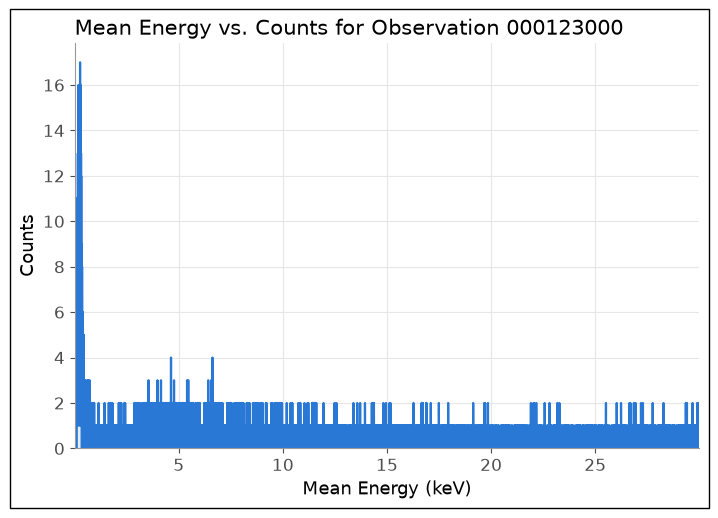

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter

x, y = np.asarray(EMean[:-1]), np.asarray(Counts[:-1])

style = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
}
with plt.rc_context(style):
    fig, ax = plt.subplots(figsize=(7, 5))

    ax.step(x, y, where="mid", color="#2a78d6", lw=1.6)
    # ax.plot(x, y, color="#2a78d6", lw=1.6)   # plain line through the points instead
    ax.fill_between(x, y, step="mid", color="#2a78d6", alpha=0.12, lw=0)

    ax.set_title(f"Mean Energy vs. Counts for Observation {obsID}", loc="left")
    ax.set_xlabel("Mean Energy (keV)")
    ax.set_ylabel("Counts")
    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))   # 12,000 rather than 12000
    # ax.set_yscale("log"); ax.set_ylim(bottom=max(y[y > 0].min() / 2, 0.5))  # if counts span many decades

    # quiet axes and grid so the spectrum stands out
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("0.6")
    ax.tick_params(colors="0.3")
    ax.grid(True, color="0.9", lw=0.8)
    ax.set_axisbelow(True)

    fig.tight_layout(pad=0.6)

    # black border, inset by half its width so no side is clipped
    lw = 1
    dx, dy = (lw / 2 / 72) / fig.get_figwidth(), (lw / 2 / 72) / fig.get_figheight()
    fig.add_artist(Rectangle((dx, dy), 1 - 2 * dx, 1 - 2 * dy, transform=fig.transFigure,
                             fill=False, edgecolor="black", linewidth=lw))
    plt.show()


# Run once for a given value, as a test

To get an idea of what the analysis looks like for a single line, we can run it once and visualize the results. To view different energy ranges, just change the value of lineVal.

Running for line value 5.0, ALP mass 10.0 keV, ALP half-life 1e+25 seconds
FOR ENERGY 5.0, Test Stat: 0.0
TS improvement: 0.0
Best-fit amplitude: 0.0
Amplitude scan max: 10.0
Profile min index: 0
Best fit signal amplitude: 0.0 
Best fit back|ground logA: -5.0 
Best fit background power law slope: 5.0 
Best Fit Test Statistic: 0.0


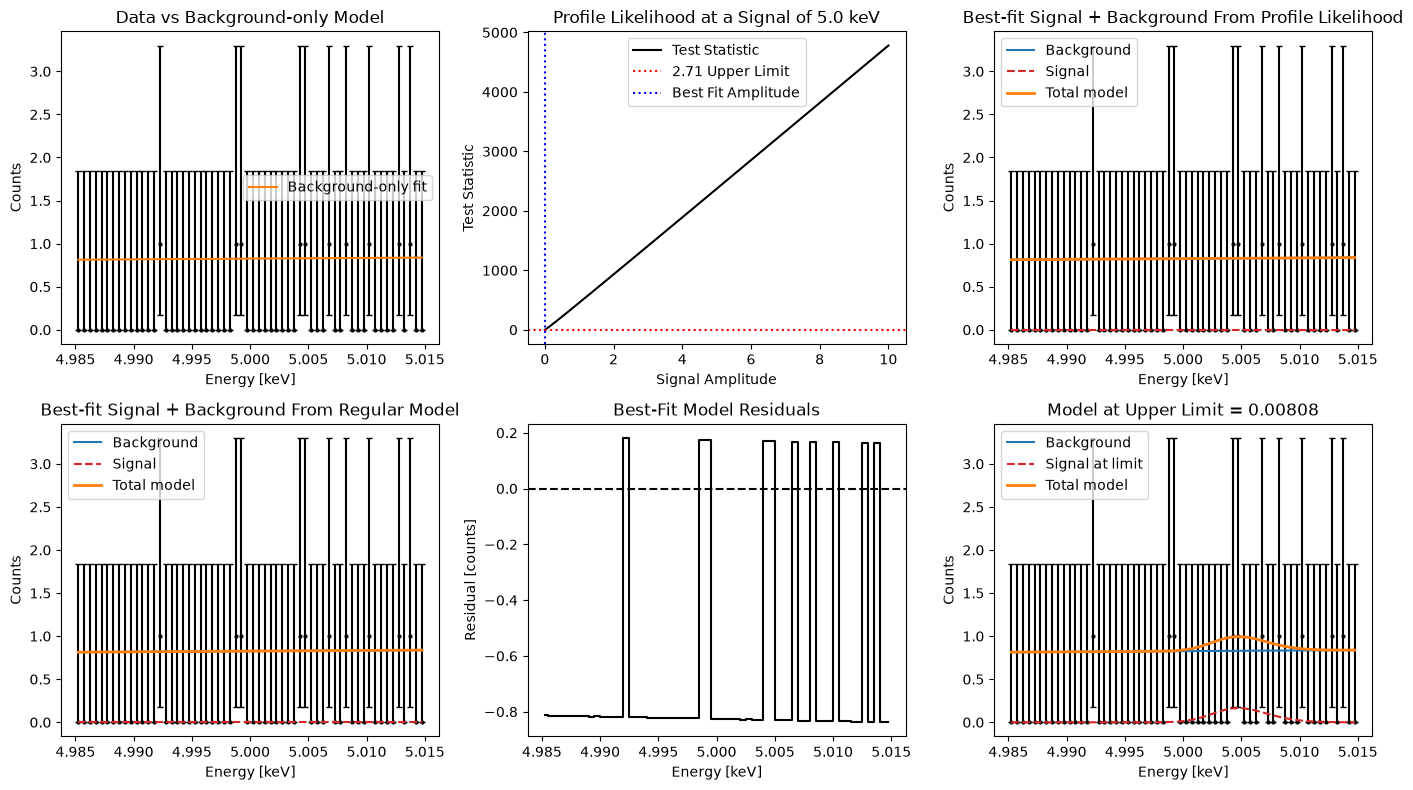

In [11]:
lineVal = 5.0 #This can be anything you like

backgroundParams, signalParams, profileSignal, bestFitTestStat, bestFit, bfList, A_sig_array, testStat, limit_signal_strength, reducedVals = runPipeline(Counts, Det_res, Exp, Cin_min, Cin_max, EMean, dE, lineVal, window=0.015, tauChi=1e25, lval=l, bval=b)
print(f"Best fit signal amplitude: {profileSignal[0]} \nBest fit back|ground logA: {profileSignal[1]} \nBest fit background power law slope: {profileSignal[2]} \nBest Fit Test Statistic: {bestFitTestStat}")
fig, axes = relevantPlots(EMean, Counts, backgroundParams, signalParams, profileSignal, bfList, A_sig_array, testStat, limit_signal_strength, reducedVals, lineVal, Exp)

# Full Analysis for an Observation

In [22]:
lineVals = []

#This sets our range of values - you can change the interval (the third argument) to make it finer or coarser, as you like. My final analysis uses an interval of 0.01
lineVals = np.arange(1.65, 18.01, 0.05)

discoveryTestStats = []
upperLims = []
mChiVals = [energy * 2 for energy in lineVals]

for lineVal in lineVals:
    print("Run number", int((lineVal - baseVal)/0.05 + 0.1))
    backgroundParams, signalParams, profileSignal, bestFitTestStat, bestFit, bfList, A_sig_array, testStat, limit_signal_strength, reducedVals = runPipeline(Counts, Det_res, Exp, Cin_min, Cin_max, EMean, dE, lineVal, window=0.015, tauChi=1e25, lval=l, bval=b)

    discoveryTestStats.append(testStat[0])
    upperLims.append(limit_signal_strength)

Run number 0
Running for line value 1.65, ALP mass 3.3 keV, ALP half-life 1e+25 seconds
FOR ENERGY 1.65, Test Stat: 4.696687483374262e-11
TS improvement: 4.696687483374262e-11
Best-fit amplitude: 0.0
Amplitude scan max: 10.0
Profile min index: 0
Run number 1
Running for line value 1.7, ALP mass 3.4 keV, ALP half-life 1e+25 seconds
FOR ENERGY 1.7, Test Stat: 4.092726157978177e-12
TS improvement: 4.092726157978177e-12
Best-fit amplitude: 0.0
Amplitude scan max: 10.0
Profile min index: 0
Run number 2
Running for line value 1.75, ALP mass 3.5 keV, ALP half-life 1e+25 seconds
FOR ENERGY 1.75, Test Stat: 0.0
TS improvement: 0.0
Best-fit amplitude: 0.0
Amplitude scan max: 10.0
Profile min index: 0
Run number 3
Running for line value 1.8, ALP mass 3.6 keV, ALP half-life 1e+25 seconds
FOR ENERGY 1.8, Test Stat: 0.0
TS improvement: 0.0
Best-fit amplitude: 0.0
Amplitude scan max: 10.0
Profile min index: 0
Run number 4
Running for line value 1.85, ALP mass 3.7 keV, ALP half-life 1e+25 seconds
FOR 

Text(0, 0.5, 'Discovery Test Statistic')

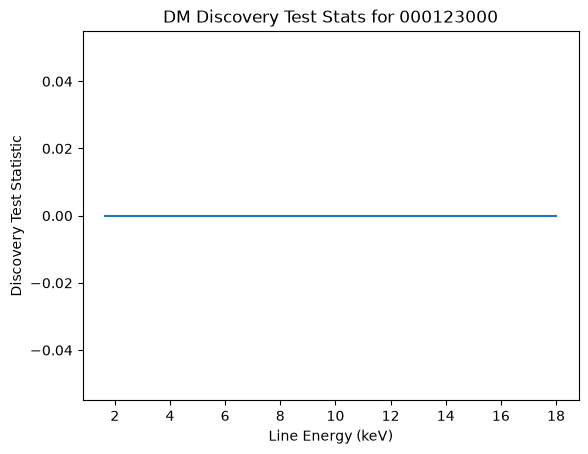

In [26]:
#DM discovery significance
plt.plot(lineVals, discoveryTestStats)
plt.title(f"DM Discovery Test Stats for {obsID}")
plt.xlabel("Line Energy (keV)")
plt.ylabel("Discovery Test Statistic")

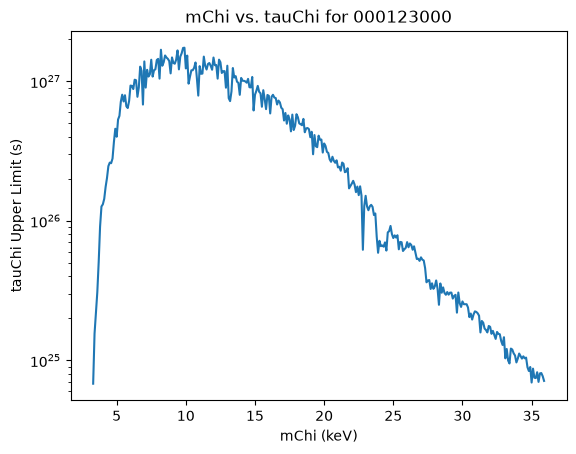

In [27]:
#Upper limits to DM lifetime as a function of DM mass
aSigUpperLim = np.array(upperLims)
tauChiVals = 1e25/aSigUpperLim
plt.plot(mChiVals, tauChiVals)
plt.title(f"mChi vs. tauChi for {obsID}")
plt.xlabel("mChi (keV)")
plt.ylabel("tauChi Upper Limit (s)")
plt.yscale('log')

Running for line value 1.65, ALP mass 3.3 keV, ALP half-life 1e+25 seconds
FOR ENERGY 1.65, Test Stat: 4.696687483374262e-11
TS improvement: 4.696687483374262e-11
Best-fit amplitude: 0.0
Amplitude scan max: 10.0
Profile min index: 0
Best fit signal amplitude: 0.0 
Best fit back|ground logA: -5.0 
Best fit background power law slope: -0.2636299055313558 
Best Fit Test Statistic: 4.696687483374262e-11


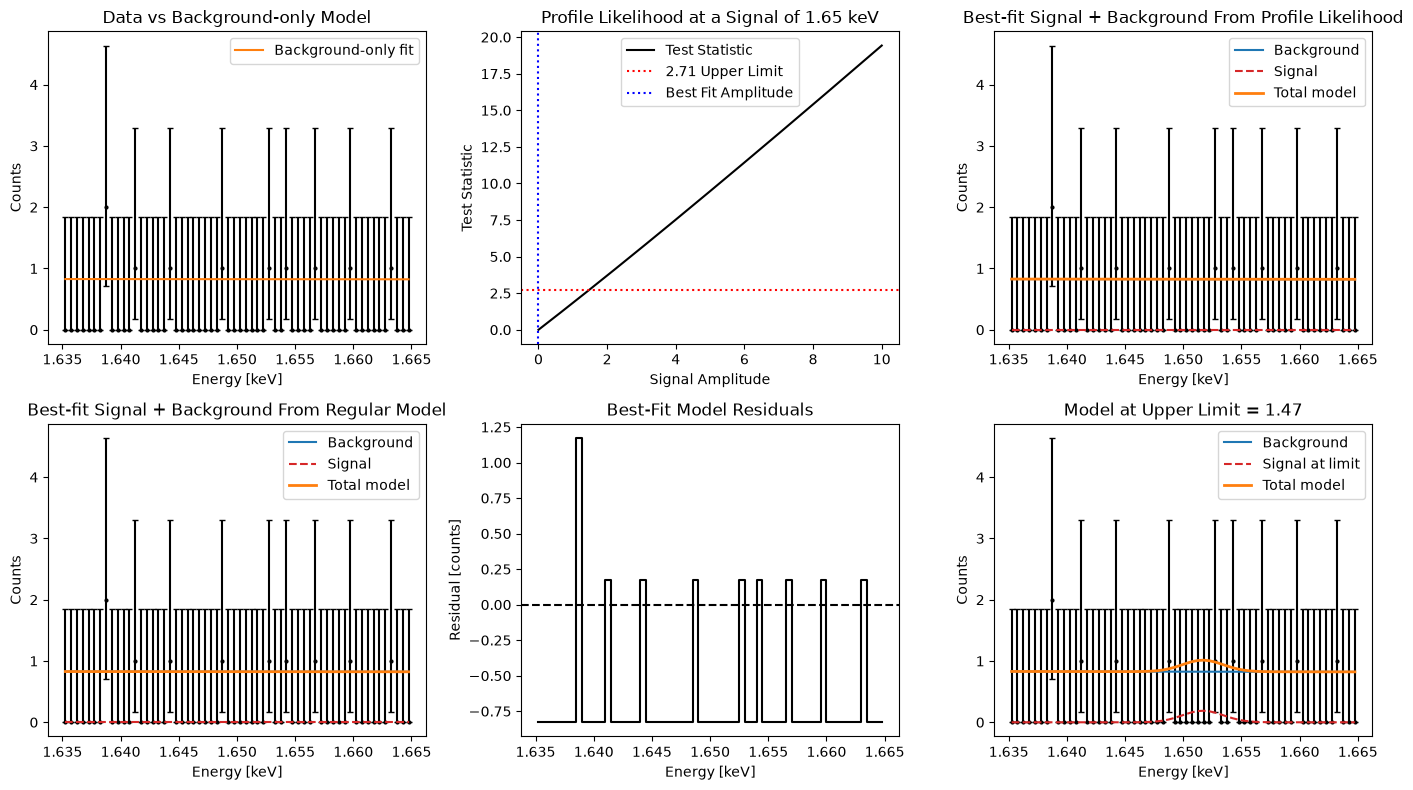

In [28]:
#We can also specifically take a look at the best fit for the signal
lineVal = lineVals[np.argmax(discoveryTestStats)]
backgroundParams, signalParams, profileSignal, bestFitTestStat, bestFit, bfList, A_sig_array, testStat, limit_signal_strength, reducedVals = runPipeline(Counts, Det_res, Exp, Cin_min, Cin_max, EMean, dE, lineVal, window=0.015, tauChi=1e25, lval=l, bval=b)
print(f"Best fit signal amplitude: {profileSignal[0]} \nBest fit back|ground logA: {profileSignal[1]} \nBest fit background power law slope: {profileSignal[2]} \nBest Fit Test Statistic: {bestFitTestStat}")
fig, axes = relevantPlots(EMean, Counts, backgroundParams, signalParams, profileSignal, bfList, A_sig_array, testStat, limit_signal_strength, reducedVals, lineVal, Exp)

# Appendix 1 - Plotting the Effective Area

Filename: fileStorage3/300073010/outputFile.arf
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       8   ()      
  1  SPECRESP      1 BinTableHDU     81   60000R x 3C   [E, E, E]   
None
ColDefs(
    name = 'ENERG_LO'; format = 'E'; unit = 'keV'
    name = 'ENERG_HI'; format = 'E'; unit = 'keV'
    name = 'SPECRESP'; format = 'E'; unit = 'cm^2'
)


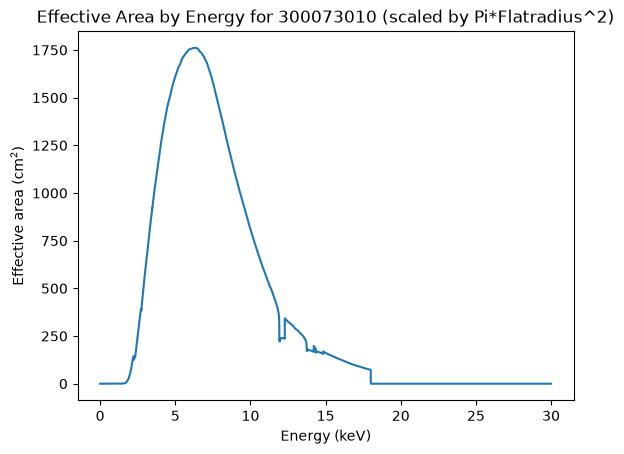

In [25]:
arfFile = str('fileStorage3/' + str(obsID) + '/outputFile.arf')
with fits.open(arfFile) as hdul:
    print(hdul.info())
    data = hdul[1].data
    print(data.columns)

elo = data["ENERG_LO"]
ehi = data["ENERG_HI"]
area = np.array(data["SPECRESP"])

energy = 0.5 * (elo + ehi)

arcsec2_to_sr = 2.350443e-11
roiFactor = np.pi * (10 * 60)**2 * arcsec2_to_sr 

plt.plot(energy, [val*100*np.pi for val in area])
#plt.plot(energy, effA/deltaOmega)
plt.title(f"Effective Area by Energy for {obsID} (scaled by Pi*Flatradius^2)")
plt.xlabel("Energy (keV)")
plt.ylabel("Effective area (cm$^2$)")
plt.show()